## Этап 3, часть 2. Предобработка данных матчей CS2 на FACEIT

Кукин Олег АД-24

[Датасет на Kaggle](https://www.kaggle.com/datasets/piercehentosh/counter-strike-2-win-prediction-faceit)

## 1 Загрузка данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [2]:
df = pd.read_csv("win_prediction_data_clean1.csv", sep=";")

## 2 Проверка и очистка данных

In [3]:
df.isna().sum()

,0
win,0
map,0
Team_A_avg_win_percentage,0
Team_A_avg_KR,0
Team_A_avg_elo,0
Team_B_avg_win_percentage,0
Team_B_avg_KR,0
Team_B_avg_elo,0
Match ID,0


In [4]:
print("Полных дубликатов:", df.duplicated().sum())
print("Повторных записей по ID сверх первой:", df["Match ID"].duplicated().sum())

Полных дубликатов: 0
Повторных записей по ID сверх первой: 534


In [5]:
print("Процент побед A вне 0-100:", ((df["Team_A_avg_win_percentage"] < 0) | (df["Team_A_avg_win_percentage"] > 100)).sum())
print("Процент побед B вне 0-100:", ((df["Team_B_avg_win_percentage"] < 0) | (df["Team_B_avg_win_percentage"] > 100)).sum())
print("K/R A ниже нуля:", (df["Team_A_avg_KR"] < 0).sum())
print("K/R B ниже нуля:", (df["Team_B_avg_KR"] < 0).sum())
print("ELO A не больше нуля:", (df["Team_A_avg_elo"] <= 0).sum())
print("ELO B не больше нуля:", (df["Team_B_avg_elo"] <= 0).sum())

Процент побед A вне 0-100: 0
Процент побед B вне 0-100: 0
K/R A ниже нуля: 0
K/R B ниже нуля: 0
ELO A не больше нуля: 0
ELO B не больше нуля: 0


In [6]:
df["win"].unique()

array(['team a', 'team b'], dtype=object)

In [7]:
map_counts = df.groupby("Match ID")["map"].nunique()
win_counts = df.groupby("Match ID")["win"].nunique()
print("ID с разными картами:", (map_counts > 1).sum())
print("ID с разными победителями:", (win_counts > 1).sum())

ID с разными картами: 0
ID с разными победителями: 0


In [8]:
df = df.drop_duplicates(subset="Match ID", keep="first").copy()
print("Матчей после очистки:", len(df))
print("Повторов ID после очистки:", df["Match ID"].duplicated().sum())

Матчей после очистки: 9117
Повторов ID после очистки: 0


## 3 Разделение на train и test: 80/20

In [9]:
X = df.drop(columns=["win", "Match ID"])
y = df["win"]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=(y == "team a")
)
print("Train:", len(X_train))
print("Test:", len(X_test))

Train: 7293
Test: 1824


## 4 Кодирование победителя

In [11]:
win_encoder = LabelEncoder()
y_train = win_encoder.fit_transform(y_train)
y_test = win_encoder.transform(y_test)

print("0:", win_encoder.classes_[0])
print("1:", win_encoder.classes_[1])

0: team a
1: team b


### У матча один победитель из двух, поэтому достаточно одного числа. LabelEncoder присвоил команде A код 0, команде B код 1.

## 5 Сравнение способов масштабирования ELO

### ELO измеряется в тысячах пунктов, процент побед в десятках процентов, а K/R обычно меньше единицы. Без масштабирования при сравнении матчей по расстоянию разница в ELO могла бы перевесить остальные показатели только из-за единиц измерения.

In [12]:
elo = X_train[["Team_A_avg_elo"]]
comparison = elo.copy()
comparison.columns = ["Исходный ELO"]

In [13]:
standard = StandardScaler()
comparison["StandardScaler"] = standard.fit_transform(elo)

In [14]:
minmax = MinMaxScaler()
comparison["MinMaxScaler"] = minmax.fit_transform(elo)

In [15]:
robust = RobustScaler()
comparison["RobustScaler"] = robust.fit_transform(elo)

In [16]:
comparison.describe().round(3)

,Исходный ELO,StandardScaler,MinMaxScaler,RobustScaler
count,7293.000,7293.000,7293.000,7293.000
mean,1754.907,0.000,0.310,0.106
std,414.563,1.000,0.140,0.748
min,836.000,-2.217,0.000,-1.552
25%,1453.000,-0.728,0.208,-0.439
50%,1696.200,-0.142,0.290,0.000
75%,2007.200,0.609,0.395,0.561
max,3803.800,4.943,1.000,3.803


## 6 Графики до и после масштабирования

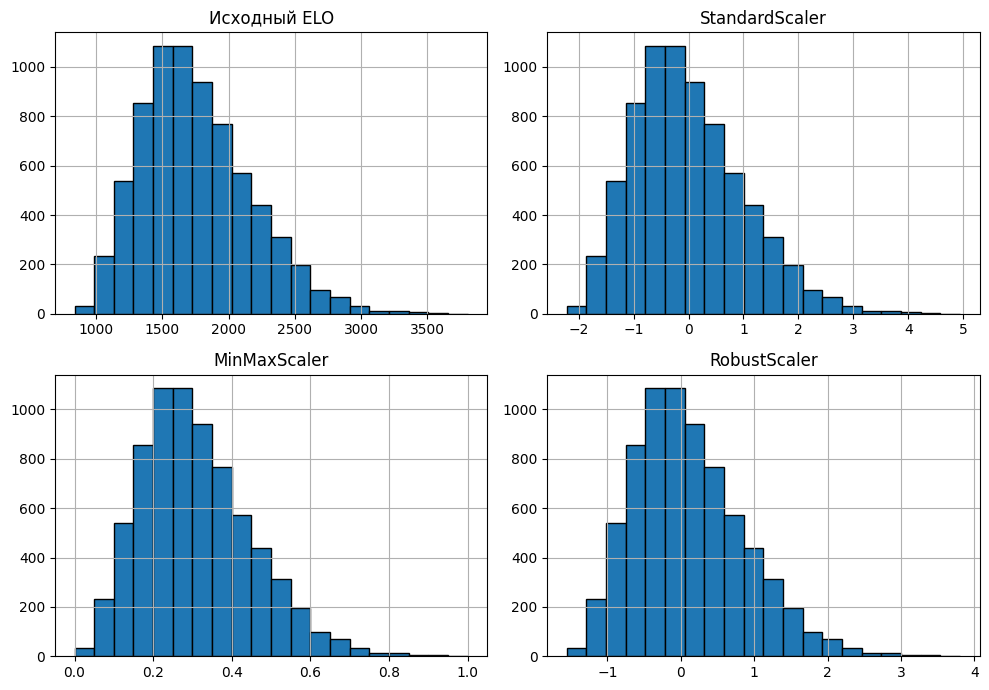

In [17]:
comparison.hist(bins=20, figsize=(10, 7), edgecolor="black")
plt.tight_layout()
plt.show()

### У StandardScaler среднее стало равно 0, у MinMaxScaler значения оказались между 0 и 1, а у RobustScaler нулём стала медиана.
### На графиках форма распределения ELO сохранилась, изменилась шкала по горизонтали. Медиана около 1696, а максимум около 3804. Я выбрал RobustScaler: его шкала зависит от средней половины значений, поэтому отдельные высокие рейтинги меньше на неё влияют.

## 7 Масштабирование числовых признаков

In [18]:
numeric_columns = [
    "Team_A_avg_win_percentage", "Team_A_avg_KR", "Team_A_avg_elo",
    "Team_B_avg_win_percentage", "Team_B_avg_KR", "Team_B_avg_elo"
]

In [19]:
scaler = RobustScaler()
X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])

## 8 Кодирование карт

### У карт нет порядка: Mirage не больше и не меньше Nuke. Поэтому выбрал OneHotEncoder: у каждой карты свой столбец. В строке матча 1 стоит у сыгранной карты, у остальных 0.

In [20]:
map_encoder = OneHotEncoder(handle_unknown="ignore", dtype="uint8")
maps_train = map_encoder.fit_transform(X_train[["map"]])
maps_test = map_encoder.transform(X_test[["map"]])
map_names = map_encoder.get_feature_names_out()

In [21]:
maps_train = pd.DataFrame.sparse.from_spmatrix(maps_train, index=X_train.index, columns=map_names)
maps_test = pd.DataFrame.sparse.from_spmatrix(maps_test, index=X_test.index, columns=map_names)

X_train = X_train[numeric_columns].join(maps_train)
X_test = X_test[numeric_columns].join(maps_test)

### На каждый матч приходится одна единица. Разреженный формат экономит память, потому что не хранит остальные нули по отдельности.

## 9 Проверка результата

In [22]:
X_train.head()

,Team_A_avg_win_percentage,Team_A_avg_KR,Team_A_avg_elo,Team_B_avg_win_percentage,Team_B_avg_KR,Team_B_avg_elo,map_de_ancient,map_de_anubis,map_de_dust2,map_de_inferno,map_de_mirage,map_de_nuke,map_de_overpass,map_de_train,map_de_vertigo
9107,-3.253369,-1.221107,-0.573439,-0.770527,-0.001525,-0.866366,0,0,0,0,0,0,0,0,1
8860,0.148480,1.226865,-0.448935,-2.075688,-2.175524,-0.006006,0,0,0,0,0,0,1,0,0
2478,0.039255,0.261544,-0.307470,0.667623,0.953978,-0.472973,0,0,0,0,1,0,0,0,0
4716,-3.973295,-4.101654,0.167088,-1.949820,-2.340119,-0.009009,0,0,0,0,0,0,0,0,1
1644,-1.610065,-1.229568,0.434500,-0.106461,-0.662497,1.298799,1,0,0,0,0,0,0,0,0


In [23]:
print("Размер train:", X_train.shape)
print("Размер test:", X_test.shape)
print("Есть пропуски в train:", X_train.isna().any().any())
print("Есть пропуски в test:", X_test.isna().any().any())
print("Одинаковые столбцы:", X_train.columns.equals(X_test.columns))

Размер train: (7293, 15)
Размер test: (1824, 15)
Есть пропуски в train: False
Есть пропуски в test: False
Одинаковые столбцы: True


In [24]:
print("Матчей на карте Train в тесте:", X_test["map_de_train"].sum())

Матчей на карте Train в тесте: 43


## 10 Вывод

### После обработки осталось 7293 матча для обучения и 1824 для проверки. В обеих таблицах одинаковые 15 признаков: 6 показателей команд и 9 столбцов карт. Данные готовы для обучения модели.